# What it really costs to send money from the UK

*Numbers Behind the Money, by Ismail Yusuf*

How much of a transfer abroad is lost to fees and exchange rates, and has that changed? This notebook analyses the World Bank's
**Remittance Prices Worldwide** dataset (Q1 2011 to Q3 2025) for every route that starts in the UK.

**Method.** Total cost = upfront fee + exchange-rate margin, as a % of the amount sent. For the UK the World Bank prices
transfers of £120 (its equivalent of $200) and £300 ($500); I use £120 unless stated. Averages are simple averages across
services, excluding services that don't disclose their exchange rate, which is the World Bank's own method.

**Data.** Download `rpw_dataset_2011_2025_q3.xlsx` (about 48 MB) from the
[World Bank Data Catalog](https://datacatalog.worldbank.org/search/dataset/0037898/remittance-prices-worldwide)
into `data/`. The first load takes about a minute; after that a cached copy is used.

In [1]:
import pandas as pd
import rpw, charts

pd.set_option("display.precision", 2)
df = rpw.load()
print(f"{len(df):,} price quotes (transparent services), {df['period'].nunique()} survey rounds, "
      f"{df['period'].min()} to {df['period'].max()}")

246,542 price quotes (transparent services), 54 survey rounds, 2011_1Q to 2025_3Q


## Check the method against the World Bank's published figure
The World Bank's published global average cost of sending $200 in Q3 2025 is 6.36%.

In [2]:
global_q3_2025 = df.loc[df["period"] == rpw.LATEST, "total"].mean()
print(f"Global average, Q3 2025: {global_q3_2025:.2f}%")

Global average, Q3 2025: 6.36%


## 1. Has sending money from the UK got cheaper?

In [3]:
tr = rpw.trend(df)
summary = tr.iloc[[0, -1]][["uk", "global", "uk_fee", "uk_fx", "services", "corridors"]]
summary.index = ["Q1 2011", "Q3 2025"]
summary

,uk,global,uk_fee,uk_fx,services,corridors
Q1 2011,7.96,8.75,5.39,2.59,364,26
Q3 2025,4.61,6.36,2.10,2.51,791,33


In [4]:
first, last = tr["uk"].iloc[0], tr["uk"].iloc[-1]
print(f"UK: {first:.2f}% -> {last:.2f}% ({(last / first - 1) * 100:.0f}%), "
      f"i.e. £{first * 1.2:.2f} -> £{last * 1.2:.2f} on £120")

routes_both, lfl, per_route = rpw.like_for_like(df)
print(f"Like-for-like ({len(routes_both)} routes surveyed in both periods): "
      f"{lfl.loc[rpw.FIRST, 'total']:.2f}% -> {lfl.loc[rpw.LATEST, 'total']:.2f}%")
print(f"Routes that got cheaper: {(per_route['change'] < 0).sum()} of {len(per_route)}")
per_route.round(2).tail(3)

UK: 7.96% -> 4.61% (-42%), i.e. £9.55 -> £5.54 on £120
Like-for-like (26 routes surveyed in both periods): 7.96% -> 4.46%
Routes that got cheaper: 24 of 26


period,2011_1Q,2025_3Q,change
destination,,,
Albania,7.41,5.84,-1.57
Bangladesh,5.07,5.11,0.04
The Gambia,6.30,12.06,5.75


## 2. The part you don't see: fee vs exchange-rate margin

In [5]:
for label, row in (("Q1 2011", tr.iloc[0]), ("Q3 2025", tr.iloc[-1])):
    print(f"{label}: fee {row['uk_fee']:.2f}%, margin {row['uk_fx']:.2f}%, "
          f"margin share of total {row['uk_fx'] / row['uk'] * 100:.0f}%")

g = df[df["period"] == rpw.LATEST]
print(f"Global margin share, Q3 2025: {g['fx'].mean() / g['total'].mean() * 100:.0f}%")

uk_now = rpw.uk(df)[lambda d: d["period"] == rpw.LATEST]
zero_fee = uk_now[uk_now["fee"] == 0]
print(f"UK services with no fee: {len(zero_fee)} of {len(uk_now)} ({len(zero_fee) / len(uk_now):.0%}); "
      f"their average cost {zero_fee['total'].mean():.2f}%, all exchange-rate margin")

Q1 2011: fee 5.39%, margin 2.59%, margin share of total 32%
Q3 2025: fee 2.10%, margin 2.51%, margin share of total 54%
Global margin share, Q3 2025: 30%
UK services with no fee: 182 of 791 (23%); their average cost 2.08%, all exchange-rate margin


## 3. Where it costs the most (Q3 2025)

In [6]:
cor = rpw.corridors(df)
print(f"Routes under 3%: {(cor['total'] < 3).sum()} of {len(cor)}; over 5%: {(cor['total'] > 5).sum()}")
cor.round(2)

Routes under 3%: 5 of 33; over 5%: 14


,services,total,fee,fx,cheapest,dearest
destination,,,,,,
India,28,1.91,1.31,0.59,0.15,3.31
Nigeria,31,1.96,1.23,0.73,-0.12,6.34
Pakistan,29,2.39,1.53,0.86,-1.43,9.28
Poland,30,2.66,1.22,1.43,0.18,13.23
Nepal,22,2.90,1.82,1.07,0.77,12.29
Sri Lanka,29,3.06,2.21,0.85,1.13,9.31
Romania,24,3.12,1.75,1.37,0.95,14.03
Philippines,38,3.33,2.33,1.00,0.44,10.82
Kenya,27,3.43,1.63,1.80,0.38,16.16


## 4. What you can control

In [7]:
ch = rpw.channels(df)
ch["cost_on_120"] = ch["total"] * 1.2
ch.round(2)

,services,total,fee,fx,cost_on_120
channel,,,,,
Online → bank account,266,2.85,1.50,1.35,3.42
Online → mobile wallet,105,3.48,0.59,2.89,4.18
Online → cash pickup,316,5.21,2.44,2.76,6.25
Cash at an agent → cash pickup,67,11.49,5.53,5.96,13.79


In [8]:
spread = cor[cor["services"] >= 10]
gap = (spread["dearest"] - spread["cheapest"]).median()
print(f"Typical gap between cheapest and dearest service on the same route: {gap:.1f} points (£{gap * 1.2:.2f} on £120)")
print(f"Average cost of sending £300: {uk_now['total_500'].mean():.2f}% vs £120: {uk_now['total'].mean():.2f}%")

Typical gap between cheapest and dearest service on the same route: 13.1 points (£15.68 on £120)
Average cost of sending £300: 3.51% vs £120: 4.61%


## 5. Can a model predict the price?
Target: total cost of sending £120 (%). Features: destination, provider type, how the sender pays, where they send from,
how the money is received, speed, receiving network coverage, and the date. The service fields start in Q2 2016.

Evaluation is time-ordered so the test is honest: train Q2 2016 to 2023, tune settings on 2024, then refit on everything
up to 2024 and score **once** on 2025. Metric: mean absolute error (MAE) in percentage points.

In [9]:
import ml
res, imp, info, by_pickup, by_route = ml.run(df, verbose=False)
print(f"Train {info['n_train']:,} | validate (2024) {info['n_valid']:,} | test (2025) {info['n_test']:,} quotes; "
      f"median 2025 cost {info['test_median']:.2f}%")
res.round(2)

Train 18,569 | validate (2024) 3,638 | test (2025) 1,625 quotes; median 2025 cost 4.04%


,valid_mae_2024,test_mae_2025
model,,
Baseline: overall median,3.08,3.01
Rule of thumb: route median,2.79,2.73
Linear model (ridge),2.38,2.36
Gradient boosting,1.84,1.70
Gradient boosting + provider name,1.45,1.39


In [10]:
base, gb = res.loc["Baseline: overall median", "test_mae_2025"], res.loc["Gradient boosting", "test_mae_2025"]
print(f"Gradient boosting cuts the error by {(1 - gb / base):.0%} versus always guessing the median")
print("Permutation importance on 2025 (extra MAE when a feature is scrambled):")
imp.rename(index=ml.LABELS).round(2).to_frame("extra error (points)")

Gradient boosting cuts the error by 43% versus always guessing the median
Permutation importance on 2025 (extra MAE when a feature is scrambled):


,extra error (points)
Destination country,1.18
How the money is received,0.58
Receiving network coverage,0.21
How the sender pays,0.21
"Where you send from (online, agent...)",0.20
Speed,0.12
Provider type,0.03
Date (trend),0.00


In [11]:
by_route.round(2).iloc[[0, 1, 2, -3, -2, -1]]

,n,mae
destination,,
Zimbabwe,49,0.85
India,58,0.96
Nepal,48,1.00
Albania,59,2.69
Ghana,77,3.92
Rwanda,43,4.45


## Charts

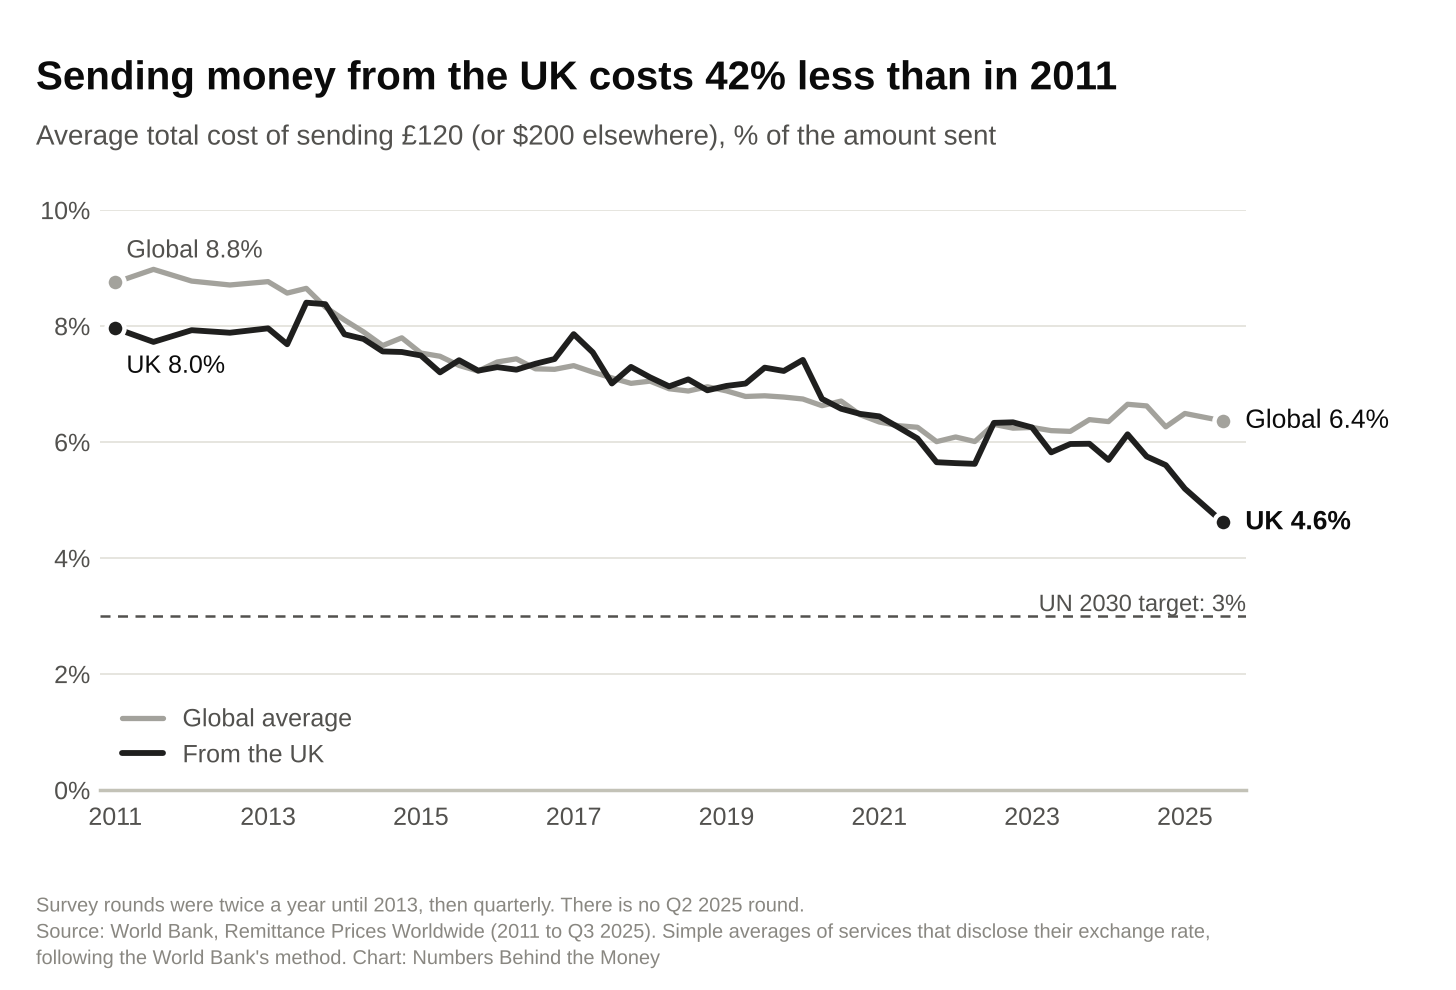

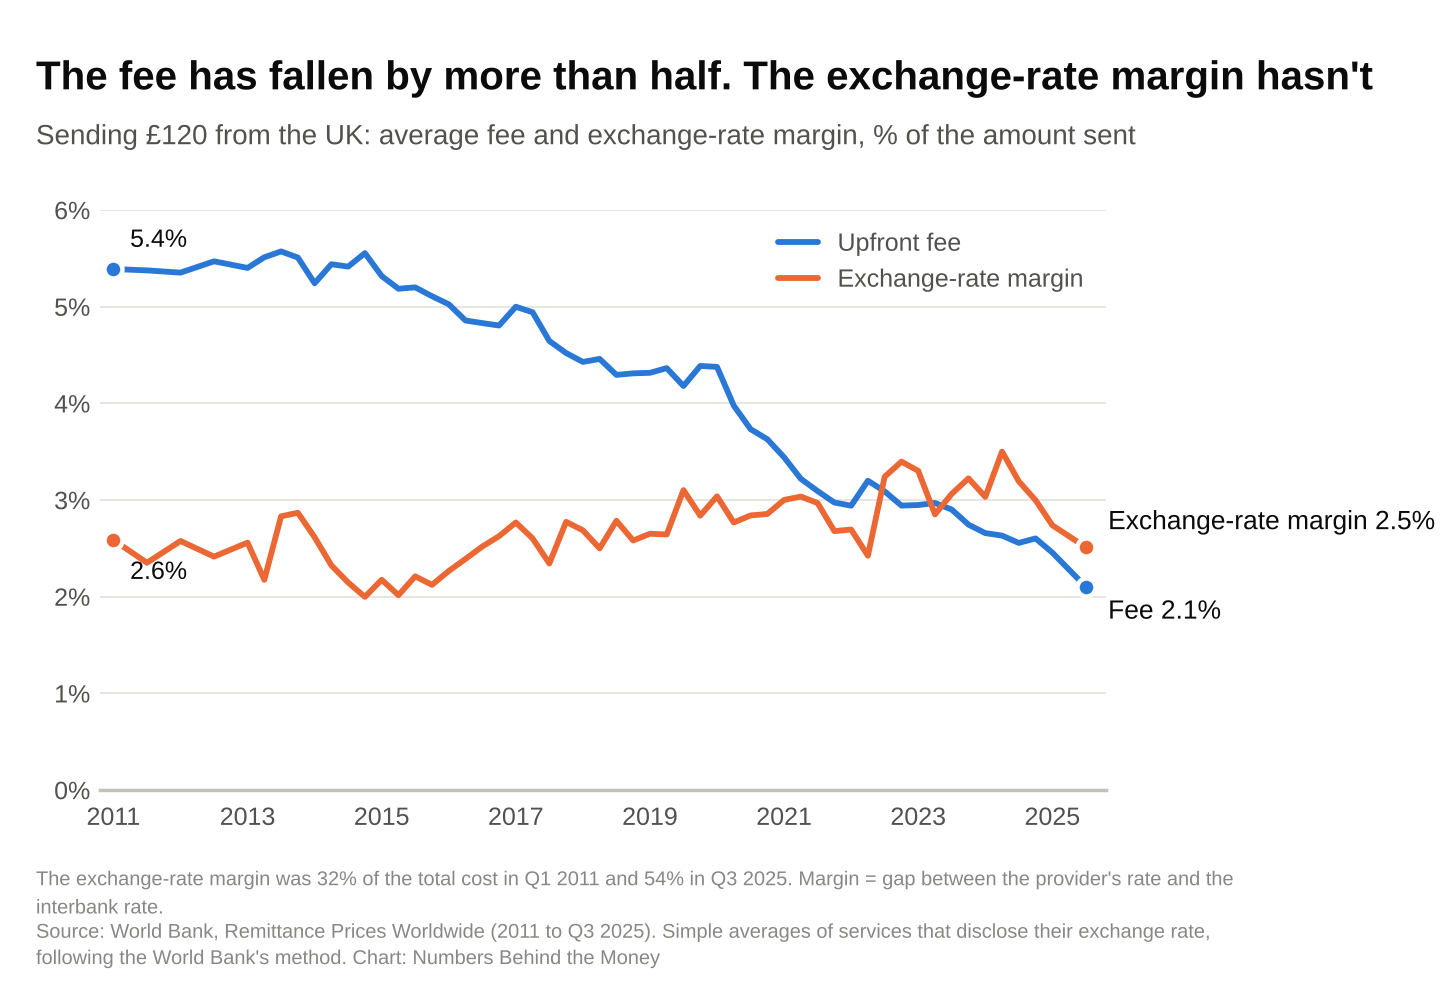

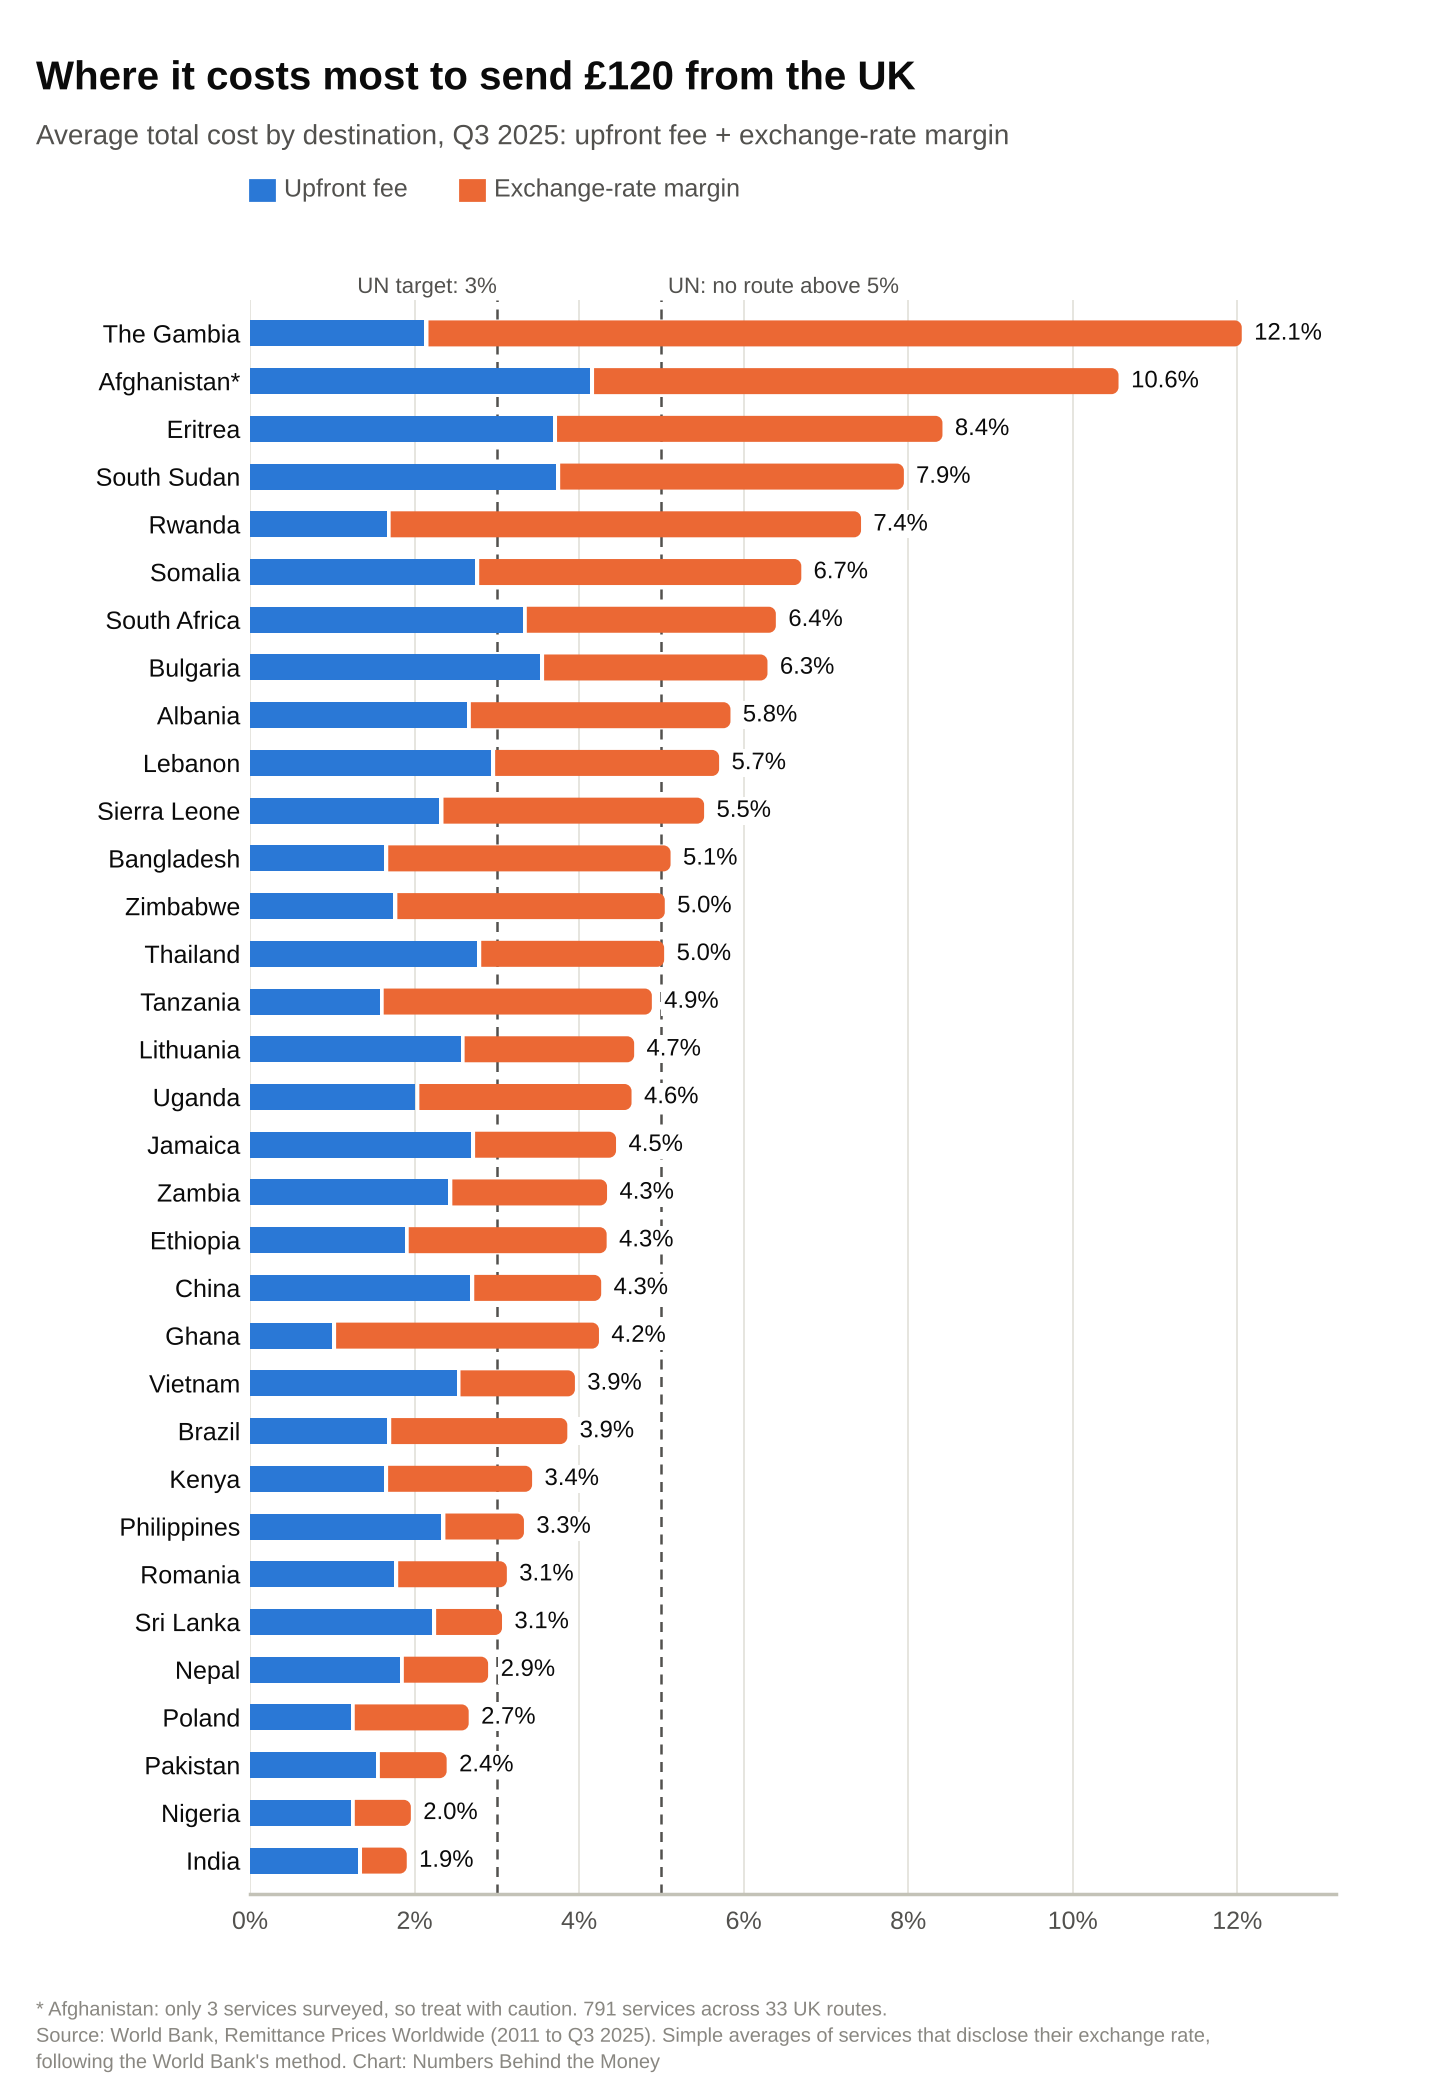

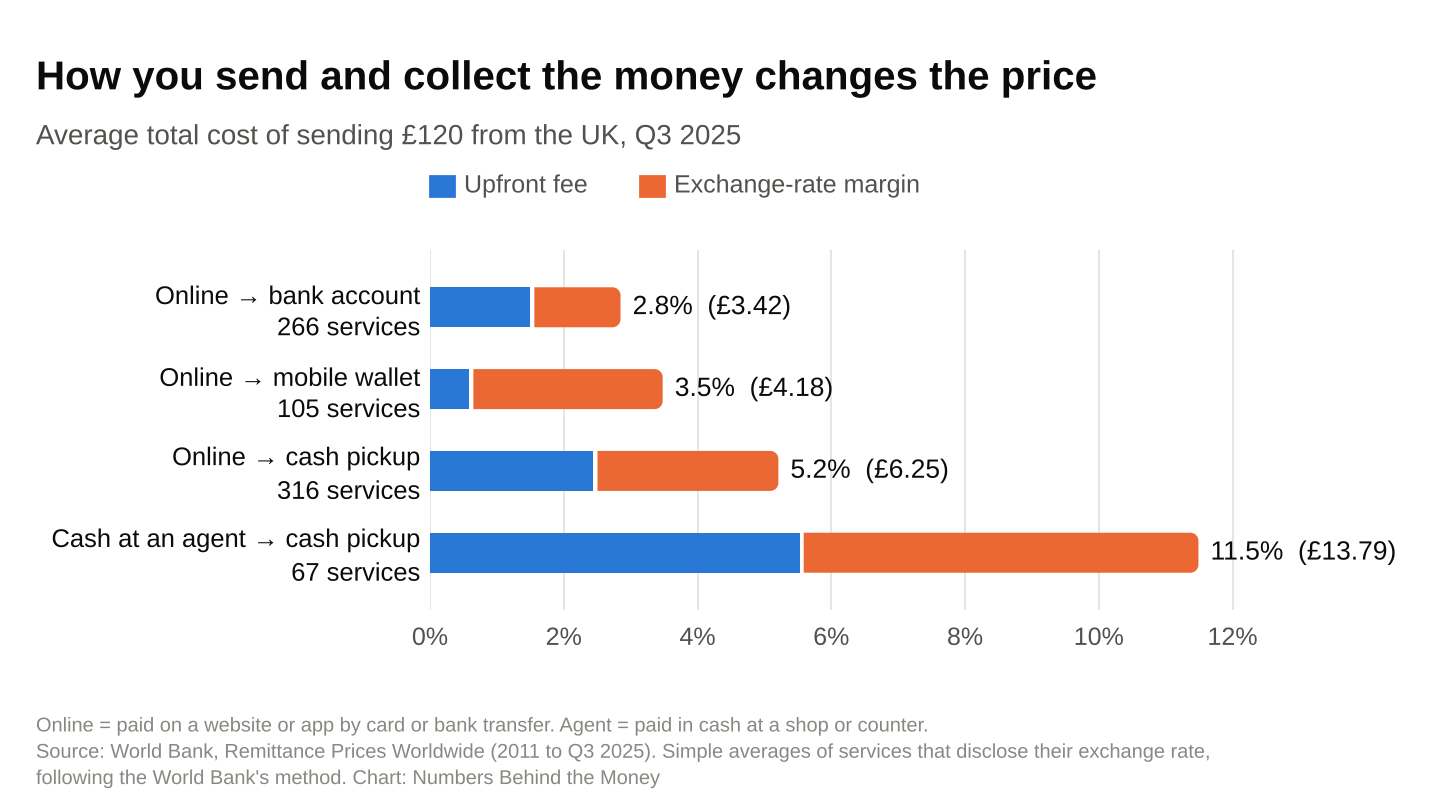

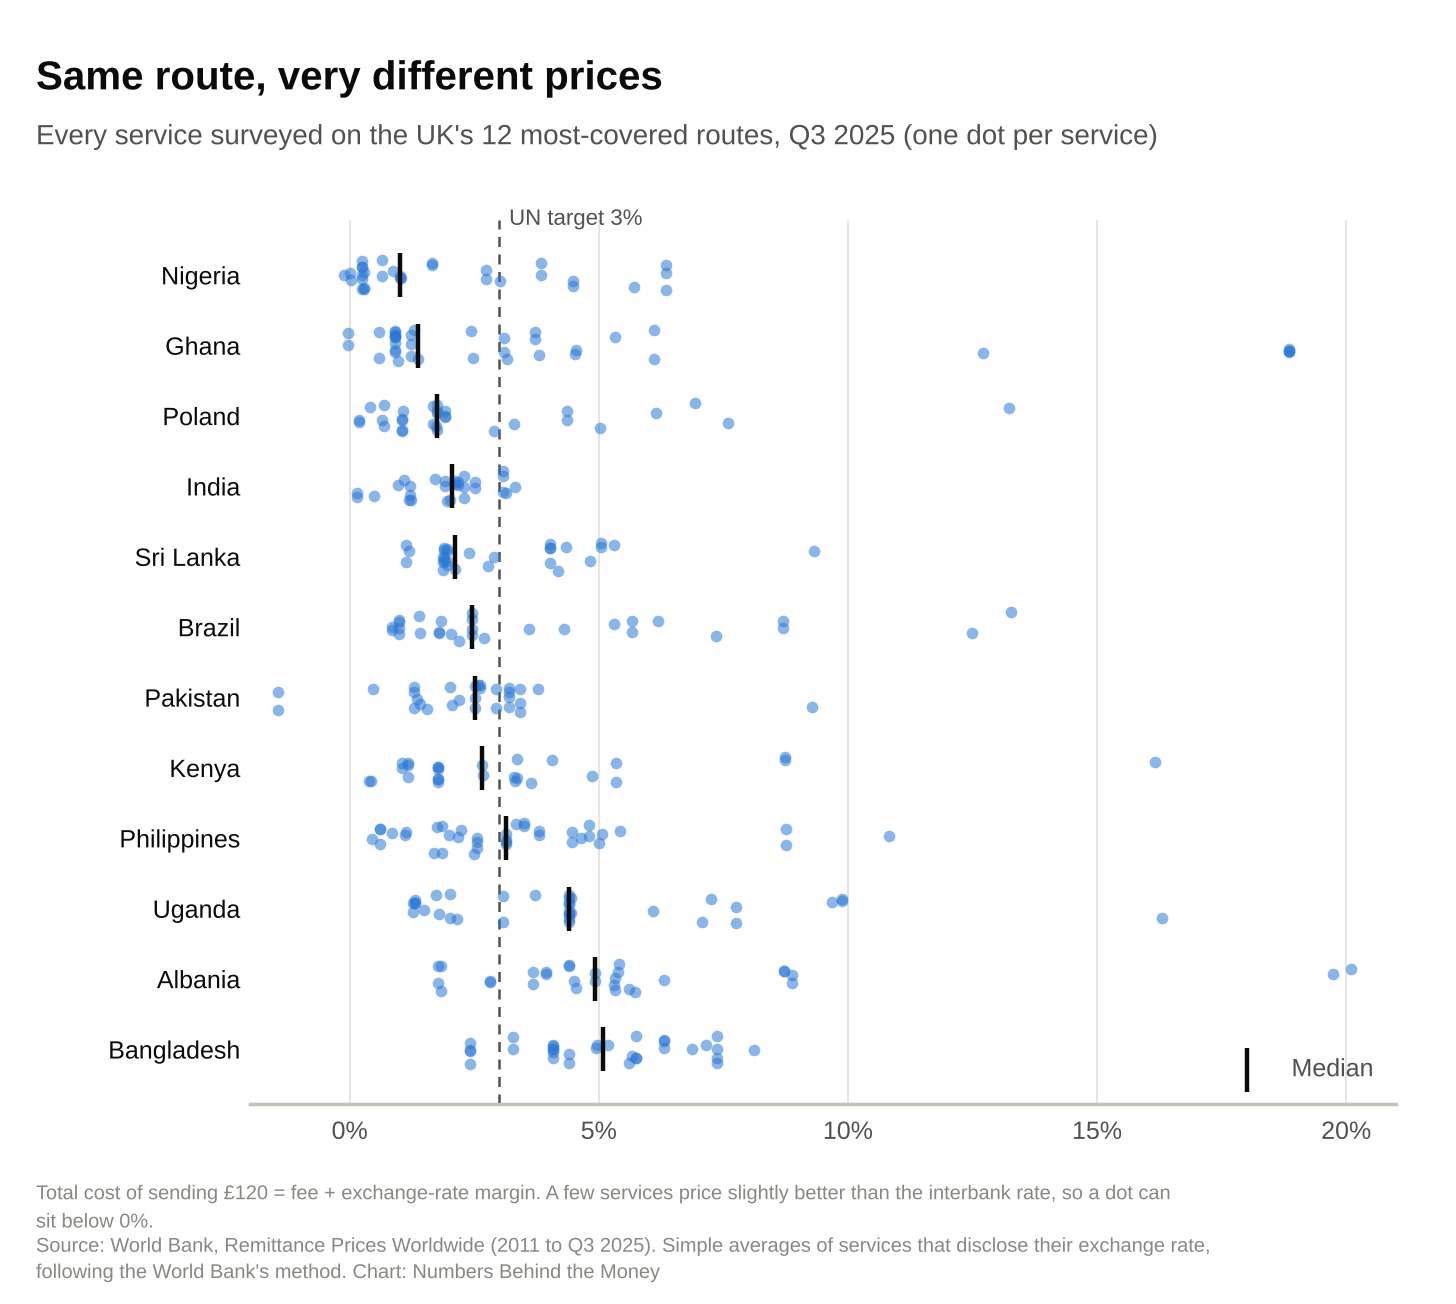

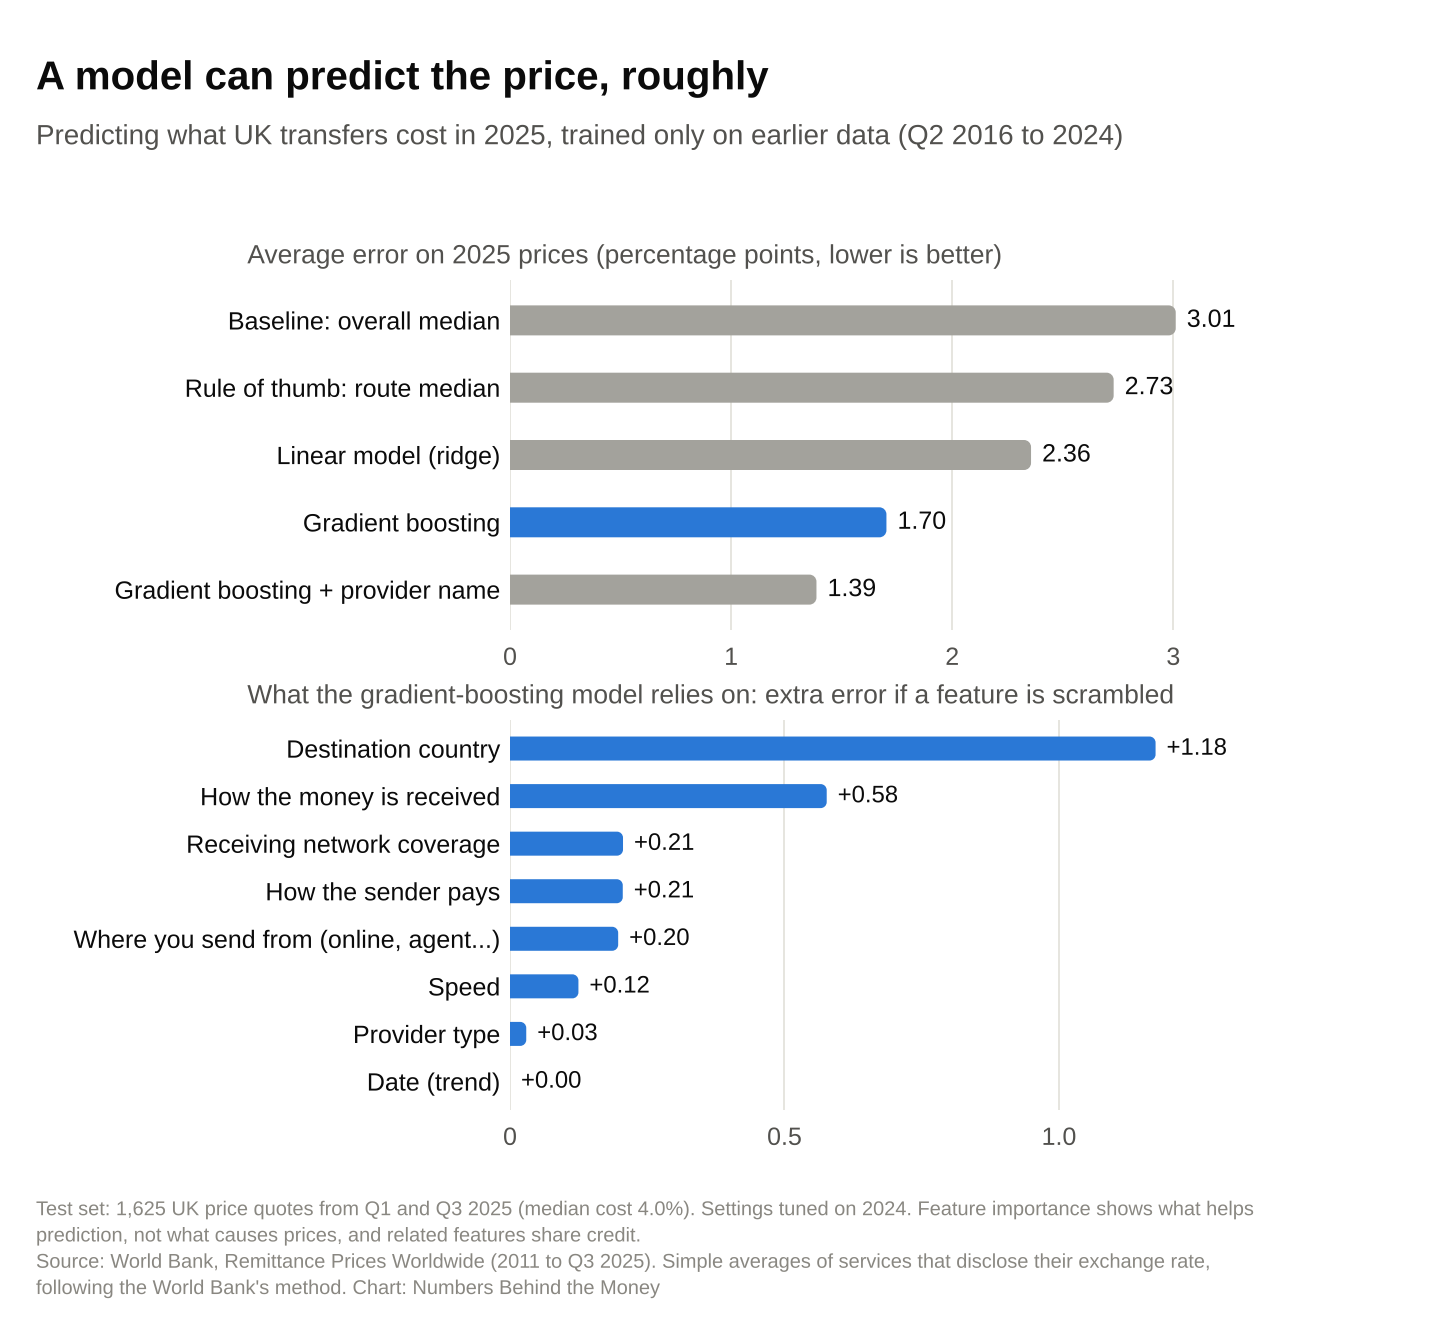

In [12]:
from pathlib import Path
from IPython.display import Image, display

out = Path("charts"); out.mkdir(exist_ok=True)
charts.chart_trend(tr, out / "chart1_trend.png")
charts.chart_split(tr, out / "chart2_fee_vs_margin.png")
charts.chart_corridors(cor, out / "chart3_routes.png")
charts.chart_channels(ch, out / "chart4_send_collect.png")
charts.chart_spread(uk_now, out / "chart5_spread.png")
charts.chart_model(res, imp, ml.LABELS, out / "chart6_model.png")
for f in sorted(out.glob("chart*.png")):
    display(Image(filename=str(f), width=728))

## Limitations
- Prices are snapshots collected on one day per round; providers change prices often.
- Simple averages treat every service equally. The data has no transaction volumes, so this is not the average price people actually pay.
- The exchange-rate margin is measured against an interbank rate. Where official and market rates differ, margins can look unusually high or negative.
- The set of UK routes grew from 26 (2011) to 33; the like-for-like check above controls for this.
- There is no Q2 2025 survey round in the dataset.
- The UK sample has about 20 bank services, mostly banks from receiving countries, so it says little about UK high-street banks.
- Feature importance shows what helps the model predict, not what causes prices; related features (how you pay, where you send from, how money is received) share credit.
- Tree models cannot extrapolate a time trend, so the date feature adds nothing for 2025; a linear trend would.

*Data: The World Bank, Remittance Prices Worldwide, remittanceprices.worldbank.org. This analysis is not endorsed by the World Bank. Analysis of public data, not financial advice.*